# Improved QSAR Model — AID 720635 (Mitochondrial Toxicity)

**Classical ML strategies:**
1. Enriched representations: Morgan + MACCS + RDKit FP + Physicochemical + Mordred
2. No-leakage preprocessing (fit on train only)
3. Variance + correlation feature selection
4. Log-transform of target if skewed
5. Stratified 5-fold CV + Bayesian Optuna tuning (XGBoost, RF, LightGBM)
6. Consensus average + Stacking (Ridge meta-learner)

**Graph Neural Network strategies:**
7. 14-dimensional enriched atom features
8. 6-dimensional bond features — **actually used** in GAT via edge_dim
9. 3-layer GCN, GAT, GIN, GraphSAGE with global mean pooling
10. 200-epoch training with ReduceLROnPlateau + early stopping

**Final comparison:** All 10 models on the same held-out test set

In [5]:
!pip install rdkit mordred optuna lightgbm xgboost scikit-learn pandas numpy matplotlib seaborn openpyxl tqdm scipy torch torch-geometric

In [6]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
np.random.seed(42)

# RDKit
from rdkit import Chem
from rdkit.Chem import AllChem, MACCSkeys, Descriptors, RDKFingerprint, rdMolDescriptors

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors

# Gradient boosting
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Bayesian optimisation
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# PyTorch + PyG (used in GNN section)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool

print('All libraries imported successfully.')

All libraries imported successfully.


## 1. Load Data

In [7]:
df = pd.read_excel(
    'AID_720635_cleaned.xlsx',
    usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE', 'PUBCHEM_ACTIVITY_OUTCOME']
)
print(f'Loaded {len(df)} records.')
print(df['PUBCHEM_ACTIVITY_SCORE'].describe())
print('\nOutcome counts:', df['PUBCHEM_ACTIVITY_OUTCOME'].value_counts().to_dict())

df['Mol'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None
)
n_before = len(df)
df = df.dropna(subset=['Mol', 'PUBCHEM_ACTIVITY_SCORE']).reset_index(drop=True)
print(f'Removed {n_before - len(df)} invalid entries. Working with {len(df)} compounds.')
mols = list(df['Mol'])

Loaded 8099 records.
count    8099.000000
mean       15.672429
std        23.805444
min         0.000000
25%         0.000000
50%        10.000000
75%        10.000000
max        99.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64

Outcome counts: {'Inconclusive': 3474, 'Inactive': 3213, 'Active': 1412}


[15:27:17] WARNING: not removing hydrogen atom without neighbors
[15:27:17] WARNING: not removing hydrogen atom without neighbors
[15:27:17] WARNING: not removing hydrogen atom without neighbors


Removed 0 invalid entries. Working with 8099 compounds.


## 2. Generate Molecular Features (Classical ML)

In [8]:
def get_morgan(mol, radius=2, nbits=2048):
    return np.array(AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits), dtype=np.uint8)

def get_maccs(mol):
    return np.array(MACCSkeys.GenMACCSKeys(mol), dtype=np.uint8)

def get_rdkfp(mol, nbits=2048):
    return np.array(RDKFingerprint(mol, fpSize=nbits), dtype=np.uint8)

def _safe(val, default=0.0):
    """Return default if val is NaN, inf, or an exception — not just on exception."""
    try:
        v = float(val)
        return default if (v != v or np.isinf(v)) else v  # v != v is True only for NaN
    except:
        return default

def get_physchem(mol):
    # MaxPartialCharge / MinPartialCharge return nan (no exception) for some molecules;
    # FractionCSP3 returns nan for all-heteroatom molecules.
    # _safe() catches both silent-nan returns and genuine exceptions.
    return np.array([
        _safe(Descriptors.MolWt(mol)),
        _safe(Descriptors.MolLogP(mol)),
        _safe(Descriptors.TPSA(mol)),
        _safe(Descriptors.NumHDonors(mol)),
        _safe(Descriptors.NumHAcceptors(mol)),
        _safe(Descriptors.NumRotatableBonds(mol)),
        sum(1 for a in mol.GetAtoms() if a.GetIsAromatic()),
        _safe(Descriptors.FractionCSP3(mol)),
        _safe(Descriptors.RingCount(mol)),
        _safe(Descriptors.MolMR(mol)),
        mol.GetNumHeavyAtoms(),
        _safe(rdMolDescriptors.CalcNumHeteroatoms(mol)),
        _safe(rdMolDescriptors.CalcNumAliphaticRings(mol)),
        _safe(rdMolDescriptors.CalcNumAromaticRings(mol)),
        _safe(Descriptors.MaxPartialCharge(mol)),
        _safe(Descriptors.MinPartialCharge(mol)),
    ], dtype=np.float64)

print('Generating Morgan (ECFP4)...')
X_morgan = np.array([get_morgan(m) for m in tqdm(mols)])
print('Generating MACCS keys...')
X_maccs  = np.array([get_maccs(m)  for m in tqdm(mols)])
print('Generating RDKit topological FP...')
X_rdk    = np.array([get_rdkfp(m)  for m in tqdm(mols)])
print('Generating physicochemical descriptors...')
X_physchem_raw = np.array([get_physchem(m) for m in tqdm(mols)])

print(f'Morgan:{X_morgan.shape}  MACCS:{X_maccs.shape}  RDKit:{X_rdk.shape}  Physchem:{X_physchem_raw.shape}')


Generating Morgan (ECFP4)...


  0%|          | 0/8099 [00:00<?, ?it/s]

[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerator
[15:27:17] DEPRECATION WARNING: please use MorganGenerat

Generating MACCS keys...


[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerator
[15:27:30] DEPRECATION WARNING: please use MorganGenerat

  0%|          | 0/8099 [00:00<?, ?it/s]

Generating RDKit topological FP...


  0%|          | 0/8099 [00:00<?, ?it/s]

Generating physicochemical descriptors...


  0%|          | 0/8099 [00:00<?, ?it/s]

Morgan:(8099, 2048)  MACCS:(8099, 167)  RDKit:(8099, 2048)  Physchem:(8099, 16)


## 3. Mordred Descriptors (2D, ~1600 features) — allow 5–10 min

In [9]:
from mordred import Calculator, descriptors as mordred_desc

print('Generating Mordred descriptors (please wait)...')
calc = Calculator(mordred_desc, ignore_3D=True)
mordred_result = calc.pandas(mols)
X_mordred_raw  = mordred_result.apply(pd.to_numeric, errors='coerce')
pct_miss = 100 * X_mordred_raw.isna().sum().sum() / X_mordred_raw.size
print(f'Mordred shape: {X_mordred_raw.shape} | Missing: {pct_miss:.2f}%')

Generating Mordred descriptors (please wait)...


  9%|▉         | 746/8099 [02:57<23:34,  5.20it/s]  

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


 10%|▉         | 798/8099 [03:23<1:14:03,  1.64it/s]

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


 27%|██▋       | 2147/8099 [05:29<06:55, 14.31it/s] 

... (15 outputs left out)

 55%|█████▌    | 4471/8099 [11:33<14:32,  4.16it/s]

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


 99%|█████████▉| 8053/8099 [45:32<00:10,  4.23it/s]  [16:13:50] WARNING: not removing hydrogen atom without neighbors
[16:13:50] WARNING: not removing hydrogen atom without neighbors
[16:13:50] WARNING: not removing hydrogen atom without neighbors
[16:13:50] WARNING: not removing hydrogen atom without neighbors
[16:13:50] WARNING: not removing hydrogen atom without neighbors
[16:13:50] WARNING: not removing hydrogen atom without neighbors
100%|██████████| 8099/8099 [45:57<00:00,  2.94it/s]


Mordred shape: (8099, 1613) | Missing: 15.77%


## 4. Target Variable Analysis

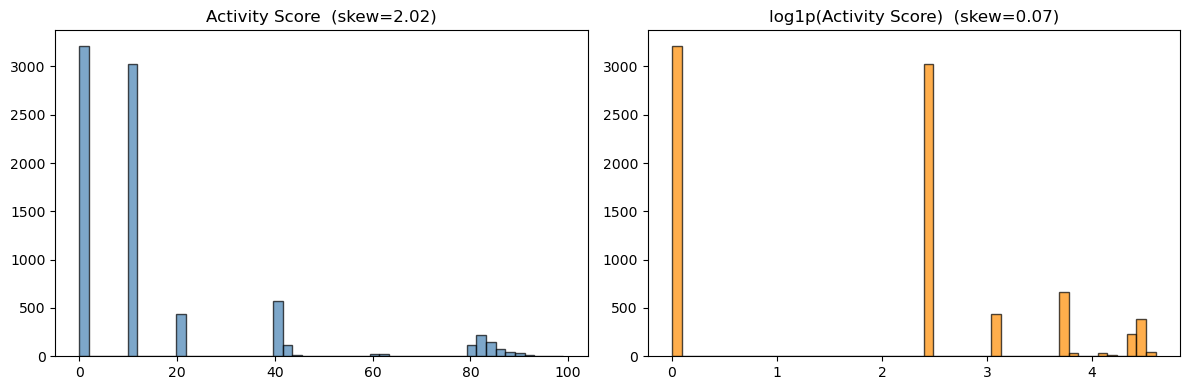

Log transform applied: True  (raw skew=2.015, log skew=0.071)


In [10]:
y_raw   = df['PUBCHEM_ACTIVITY_SCORE'].values.astype(float)
y_log   = np.log1p(y_raw)
skew_r, skew_l = stats.skew(y_raw), stats.skew(y_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_raw, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title(f'Activity Score  (skew={skew_r:.2f})')
axes[1].hist(y_log, bins=50, edgecolor='black', alpha=0.7, color='darkorange')
axes[1].set_title(f'log1p(Activity Score)  (skew={skew_l:.2f})')
plt.tight_layout(); plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight'); plt.show()

use_log  = (abs(skew_r) > 1.0) and (abs(skew_l) < abs(skew_r) - 0.5)
y_model  = y_log if use_log else y_raw.copy()
print(f'Log transform applied: {use_log}  (raw skew={skew_r:.3f}, log skew={skew_l:.3f})')

## 5. Train / Test Split  (stratified 85 / 15)

In [12]:
y_bins_all = pd.cut(y_model, bins=5, labels=False).astype(float)
y_bins_all = np.nan_to_num(y_bins_all, nan=0).astype(int)

train_idx, test_idx = train_test_split(
    np.arange(len(y_model)), test_size=0.15, random_state=42, stratify=y_bins_all
)
y_train, y_test = y_model[train_idx], y_model[test_idx]
print(f'Train: {len(train_idx)}  |  Test: {len(test_idx)}')

Train: 6884  |  Test: 1215


## 6. Feature Preprocessing (fit on train, apply to test — no leakage)

In [28]:
# ── Mordred: inf→NaN, clip extremes, impute, scale, variance/correlation filter ──
mord_raw_tr = X_mordred_raw.iloc[train_idx].values.astype(np.float64)
mord_raw_te = X_mordred_raw.iloc[test_idx].values.astype(np.float64)

mord_raw_tr[~np.isfinite(mord_raw_tr)] = np.nan
mord_raw_te[~np.isfinite(mord_raw_te)] = np.nan
mord_raw_tr = np.clip(mord_raw_tr, -1e9, 1e9)
mord_raw_te = np.clip(mord_raw_te, -1e9, 1e9)

mord_imp = SimpleImputer(strategy='median')
mord_tr   = mord_imp.fit_transform(mord_raw_tr)
mord_te   = mord_imp.transform(mord_raw_te)

mord_scl = StandardScaler()
mord_tr  = mord_scl.fit_transform(mord_tr)
mord_te  = mord_scl.transform(mord_te)
mord_tr  = np.clip(mord_tr, -50, 50)
mord_te  = np.clip(mord_te, -50, 50)

var_mord = VarianceThreshold(0.01)
mord_tr  = var_mord.fit_transform(mord_tr)
mord_te  = var_mord.transform(mord_te)
print(f'Mordred after variance filter: {mord_tr.shape[1]}')

print('Correlation filter on Mordred (~30 s)...')
upper    = pd.DataFrame(mord_tr).corr().abs().where(
               np.triu(np.ones((mord_tr.shape[1], mord_tr.shape[1])), k=1).astype(bool))
drop_c   = set(c for c in upper.columns if any(upper[c] > 0.95))
keep_c   = [c for c in range(mord_tr.shape[1]) if c not in drop_c]
mord_tr  = mord_tr[:, keep_c]
mord_te  = mord_te[:, keep_c]
print(f'Mordred after correlation filter: {mord_tr.shape[1]}')

# ── Physicochemical: same defensive cleaning ──────────────────────────────────
phys_raw_tr = X_physchem_raw[train_idx].copy()
phys_raw_te = X_physchem_raw[test_idx].copy()
phys_raw_tr[~np.isfinite(phys_raw_tr)] = 0.0
phys_raw_te[~np.isfinite(phys_raw_te)] = 0.0
phys_raw_tr = np.clip(phys_raw_tr, -1e9, 1e9)
phys_raw_te = np.clip(phys_raw_te, -1e9, 1e9)

phys_scl = StandardScaler()
phys_tr  = phys_scl.fit_transform(phys_raw_tr)
phys_te  = phys_scl.transform(phys_raw_te)
phys_tr  = np.clip(phys_tr, -50, 50)
phys_te  = np.clip(phys_te, -50, 50)

# ── Combine and final variance filter ─────────────────────────────────────────
X_tr_full = np.hstack([X_morgan[train_idx], X_maccs[train_idx], X_rdk[train_idx], phys_tr, mord_tr])
X_te_full = np.hstack([X_morgan[test_idx],  X_maccs[test_idx],  X_rdk[test_idx],  phys_te, mord_te])
print(f'Combined — Train: {X_tr_full.shape}  Test: {X_te_full.shape}')

var_all  = VarianceThreshold(0.01)
X_train  = var_all.fit_transform(X_tr_full)
X_test   = var_all.transform(X_te_full)
print(f'After final variance filter — Train: {X_train.shape}  Test: {X_test.shape}')

# pd.cut on a numpy array returns a numpy array in this pandas version,
# so wrap in pd.Series before calling .fillna()
y_train_bins = pd.Series(pd.cut(y_train, bins=5, labels=False)).fillna(0).astype(int).values
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Preprocessing complete. 5-fold CV ready.')


Mordred after variance filter: 1446
Correlation filter on Mordred (~30 s)...
Mordred after correlation filter: 833
Combined — Train: (6884, 5112)  Test: (1215, 5112)
After final variance filter — Train: (6884, 3611)  Test: (1215, 3611)
Preprocessing complete. 5-fold CV ready.


## 7. Baseline: Mean Predictor

In [29]:
def metrics(y_true, y_pred, label=''):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'{label:28s}  R²={r2:7.4f}  MAE={mae:7.4f}  RMSE={rmse:7.4f}')
    return r2, mae, rmse

y_pred_baseline = np.full(len(y_test), y_train.mean())
r2_base, mae_base, rmse_base = metrics(y_test, y_pred_baseline, 'Baseline (mean)')

Baseline (mean)               R²=-0.0000  MAE= 1.4094  RMSE= 1.5602


## 8. Classical ML — Bayesian Hyperparameter Tuning (Optuna)

In [30]:
# ── XGBoost ───────────────────────────────────────────────────────────────────
def xgb_obj(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 200, 1000),
             max_depth=trial.suggest_int('max_depth', 3, 10),
             learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
             min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
             subsample=trial.suggest_float('subsample', 0.6, 1.0),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 1.0),
             gamma=trial.suggest_float('gamma', 0.0, 3.0),
             reg_alpha=trial.suggest_float('reg_alpha', 1e-6, 5.0, log=True),
             reg_lambda=trial.suggest_float('reg_lambda', 1e-6, 5.0, log=True),
             random_state=42, n_jobs=-1, verbosity=0)
    return np.mean([r2_score(y_train[v], XGBRegressor(**p).fit(X_train[t], y_train[t]).predict(X_train[v]))
                    for t, v in kf.split(X_train, y_train_bins)])

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(xgb_obj, n_trials=100, show_progress_bar=True)
xgb_best = XGBRegressor(**study_xgb.best_params, random_state=42, n_jobs=-1, verbosity=0)
xgb_best.fit(X_train, y_train)
y_pred_xgb = xgb_best.predict(X_test)
r2_xgb, mae_xgb, rmse_xgb = metrics(y_test, y_pred_xgb, 'XGBoost')
print(f'  Best CV R²: {study_xgb.best_value:.4f}')

  0%|          | 0/100 [00:00<?, ?it/s]

[W 2026-02-19 05:57:26,900] Trial 37 failed with parameters: {'n_estimators': 695, 'max_depth': 7, 'learning_rate': 0.013803067486696123, 'min_child_weight': 5, 'subsample': 0.9428949815523089, 'colsample_bytree': 0.5199872341294177, 'gamma': 0.6502735493347785, 'reg_alpha': 0.0001306621860622071, 'reg_lambda': 0.0013084406461463102} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/var/folders/ny/rkzjn8lj59x_sqzx5bc50xf80000gn/T/ipykernel_53102/2865325823.py", line 13, in xgb_obj
    return np.mean([r2_score(y_train[v], XGBRegressor(**p).fit(X_train[t], y_train[t]).predict(X_train[v]))
                                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/site-packages/xgboost/core.py", line 729, in inner_f
    retur

KeyboardInterrupt: 

In [31]:
# ── Random Forest ─────────────────────────────────────────────────────────────
def rf_obj(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 100, 800),
             max_depth=trial.suggest_categorical('max_depth', [None, 10, 20, 30, 40]),
             min_samples_split=trial.suggest_int('min_samples_split', 2, 20),
             min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 10),
             max_features=trial.suggest_float('max_features', 0.1, 0.8),
             random_state=42, n_jobs=-1)
    return np.mean([r2_score(y_train[v], RandomForestRegressor(**p).fit(X_train[t], y_train[t]).predict(X_train[v]))
                    for t, v in kf.split(X_train, y_train_bins)])

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(rf_obj, n_trials=60, show_progress_bar=True)
rf_best = RandomForestRegressor(**study_rf.best_params, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)
r2_rf, mae_rf, rmse_rf = metrics(y_test, y_pred_rf, 'Random Forest')
print(f'  Best CV R²: {study_rf.best_value:.4f}')

  0%|          | 0/60 [00:00<?, ?it/s]

[W 2026-02-19 05:57:45,805] Trial 0 failed with parameters: {'n_estimators': 362, 'max_depth': None, 'min_samples_split': 3, 'min_samples_leaf': 9, 'max_features': 0.5207805082202462} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/var/folders/ny/rkzjn8lj59x_sqzx5bc50xf80000gn/T/ipykernel_53102/3887697598.py", line 9, in rf_obj
    return np.mean([r2_score(y_train[v], RandomForestRegressor(**p).fit(X_train[t], y_train[t]).predict(X_train[v]))
                                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/site-p

KeyboardInterrupt: 

In [ ]:
# ── LightGBM ──────────────────────────────────────────────────────────────────
def lgbm_obj(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 200, 1000),
             num_leaves=trial.suggest_int('num_leaves', 20, 150),
             max_depth=trial.suggest_int('max_depth', 3, 12),
             learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
             min_child_samples=trial.suggest_int('min_child_samples', 5, 50),
             subsample=trial.suggest_float('subsample', 0.6, 1.0),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 1.0),
             reg_alpha=trial.suggest_float('reg_alpha', 1e-6, 5.0, log=True),
             reg_lambda=trial.suggest_float('reg_lambda', 1e-6, 5.0, log=True),
             random_state=42, n_jobs=-1, verbose=-1)
    return np.mean([r2_score(y_train[v], LGBMRegressor(**p).fit(X_train[t], y_train[t]).predict(X_train[v]))
                    for t, v in kf.split(X_train, y_train_bins)])

study_lgbm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm.optimize(lgbm_obj, n_trials=100, show_progress_bar=True)
lgbm_best = LGBMRegressor(**study_lgbm.best_params, random_state=42, n_jobs=-1, verbose=-1)
lgbm_best.fit(X_train, y_train)
y_pred_lgbm = lgbm_best.predict(X_test)
r2_lgbm, mae_lgbm, rmse_lgbm = metrics(y_test, y_pred_lgbm, 'LightGBM')
print(f'  Best CV R²: {study_lgbm.best_value:.4f}')

## 9. Consensus Average + Stacking Ensemble

In [ ]:
# ── Consensus average ─────────────────────────────────────────────────────────
y_pred_avg = (y_pred_xgb + y_pred_rf + y_pred_lgbm) / 3.0
r2_avg, mae_avg, rmse_avg = metrics(y_test, y_pred_avg, 'Consensus (avg)')

# ── Stacking (Ridge meta-learner) ─────────────────────────────────────────────
oof_xgb = np.zeros(len(X_train))
oof_rf  = np.zeros(len(X_train))
oof_lgb = np.zeros(len(X_train))

for t, v in kf.split(X_train, y_train_bins):
    m1 = XGBRegressor(**study_xgb.best_params,  random_state=42, n_jobs=-1, verbosity=0).fit(X_train[t], y_train[t])
    m2 = RandomForestRegressor(**study_rf.best_params, random_state=42, n_jobs=-1).fit(X_train[t], y_train[t])
    m3 = LGBMRegressor(**study_lgbm.best_params, random_state=42, n_jobs=-1, verbose=-1).fit(X_train[t], y_train[t])
    oof_xgb[v] = m1.predict(X_train[v])
    oof_rf[v]  = m2.predict(X_train[v])
    oof_lgb[v] = m3.predict(X_train[v])

meta = Ridge(alpha=1.0)
meta.fit(np.column_stack([oof_xgb, oof_rf, oof_lgb]), y_train)
y_pred_stack = meta.predict(np.column_stack([y_pred_xgb, y_pred_rf, y_pred_lgbm]))
r2_stack, mae_stack, rmse_stack = metrics(y_test, y_pred_stack, 'Stacking (Ridge)')
print(f'  Meta weights — XGB:{meta.coef_[0]:.3f}  RF:{meta.coef_[1]:.3f}  LGBM:{meta.coef_[2]:.3f}')

---
## 10. Graph Neural Networks
### 10a. Build Graph Objects
**Atom features (14-dim):** atomic number, degree, formal charge, hybridisation, aromaticity, H count, radical electrons, ring membership, normalised mass, one-hot element (C, N, O, S, halogen)

**Bond features (6-dim):** one-hot bond type (single/double/triple/aromatic), conjugated, in ring — **passed to GAT via `edge_dim`**

In [ ]:
BOND_TYPE_MAP = {
    Chem.rdchem.BondType.SINGLE:   [1, 0, 0, 0],
    Chem.rdchem.BondType.DOUBLE:   [0, 1, 0, 0],
    Chem.rdchem.BondType.TRIPLE:   [0, 0, 1, 0],
    Chem.rdchem.BondType.AROMATIC: [0, 0, 0, 1],
}
ATOM_DIM = 14
BOND_DIM = 6

def atom_feat(atom):
    return [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetFormalCharge(),
        int(atom.GetHybridization()),
        int(atom.GetIsAromatic()),
        atom.GetTotalNumHs(),
        atom.GetNumRadicalElectrons(),
        int(atom.IsInRing()),
        round(atom.GetMass() / 100.0, 4),
        int(atom.GetAtomicNum() == 6),
        int(atom.GetAtomicNum() == 7),
        int(atom.GetAtomicNum() == 8),
        int(atom.GetAtomicNum() == 16),
        int(atom.GetAtomicNum() in (9, 17, 35, 53)),
    ]

def bond_feat(bond):
    bt = BOND_TYPE_MAP.get(bond.GetBondType(), [0, 0, 0, 0])
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]

def mol_to_graph(mol, target):
    x  = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i, j], [j, i]]
        ea += [bf,     bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr  = torch.empty((0, BOND_DIM), dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([target], dtype=torch.float))

print('Building graph objects...')
data_list = [mol_to_graph(mols[i], y_model[i]) for i in tqdm(range(len(mols)))]
print(f'Generated {len(data_list)} graphs.')
print(f'Example graph: {data_list[0]}')
print(f'Atom feat dim: {data_list[0].x.shape[1]}, Bond feat dim: {data_list[0].edge_attr.shape[1]}')

### 10b. Graph Data Split (same train/test indices as classical ML)

In [ ]:
# Same outer split as classical ML for a fair comparison
data_train_all = [data_list[i] for i in train_idx]
data_test_geo  = [data_list[i] for i in test_idx]

# Carve 10% of train for GNN validation (early stopping)
n_gval         = max(1, int(0.10 * len(data_train_all)))
data_gnn_train = data_train_all[:-n_gval]
data_gnn_val   = data_train_all[-n_gval:]

BATCH = 32
loader_tr   = PyGLoader(data_gnn_train, batch_size=BATCH, shuffle=True)
loader_val  = PyGLoader(data_gnn_val,   batch_size=BATCH, shuffle=False)
loader_test = PyGLoader(data_test_geo,  batch_size=BATCH, shuffle=False)

print(f'GNN — train: {len(data_gnn_train)}, val: {len(data_gnn_val)}, test: {len(data_test_geo)}')

### 10c. GNN Model Definitions
All models share the same backbone (projection → 3 conv layers → global mean pool → regression head).
**GAT** additionally uses `edge_attr` (bond features) via `edge_dim`. GCN, GIN, GraphSAGE use atom features only.

In [ ]:
class GCNModel(nn.Module):
    def __init__(self, in_dim, hidden, dropout=0.3):
        super().__init__()
        self.proj    = nn.Linear(in_dim, hidden)
        self.conv1   = GCNConv(hidden, hidden)
        self.conv2   = GCNConv(hidden, hidden)
        self.conv3   = GCNConv(hidden, hidden)
        self.drop    = nn.Dropout(dropout)
        self.out     = nn.Linear(hidden, 1)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.proj(x));  x = self.drop(x)
        x = F.relu(self.conv1(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv2(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv3(x, edge_index))
        return self.out(global_mean_pool(x, batch))


class GATModel(nn.Module):
    """Uses bond features (edge_attr) via edge_dim — concat=False keeps dim=hidden."""
    def __init__(self, in_dim, hidden, heads=4, dropout=0.3, edge_dim=BOND_DIM):
        super().__init__()
        self.proj  = nn.Linear(in_dim, hidden)
        self.conv1 = GATConv(hidden, hidden, heads=heads, concat=False, dropout=dropout, edge_dim=edge_dim)
        self.conv2 = GATConv(hidden, hidden, heads=heads, concat=False, dropout=dropout, edge_dim=edge_dim)
        self.conv3 = GATConv(hidden, hidden, heads=heads, concat=False, dropout=dropout, edge_dim=edge_dim)
        self.drop  = nn.Dropout(dropout)
        self.out   = nn.Linear(hidden, 1)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.proj(x));  x = self.drop(x)
        x = F.relu(self.conv1(x, edge_index, edge_attr)); x = self.drop(x)
        x = F.relu(self.conv2(x, edge_index, edge_attr)); x = self.drop(x)
        x = F.relu(self.conv3(x, edge_index, edge_attr))
        return self.out(global_mean_pool(x, batch))


class GINModel(nn.Module):
    def __init__(self, in_dim, hidden, dropout=0.3):
        super().__init__()
        self.proj = nn.Linear(in_dim, hidden)
        def mlp(d): return nn.Sequential(nn.Linear(d, d), nn.BatchNorm1d(d), nn.ReLU(), nn.Linear(d, d))
        self.conv1 = GINConv(mlp(hidden), train_eps=True)
        self.conv2 = GINConv(mlp(hidden), train_eps=True)
        self.conv3 = GINConv(mlp(hidden), train_eps=True)
        self.drop  = nn.Dropout(dropout)
        self.out   = nn.Linear(hidden, 1)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.proj(x));  x = self.drop(x)
        x = F.relu(self.conv1(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv2(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv3(x, edge_index))
        return self.out(global_mean_pool(x, batch))


class GraphSAGEModel(nn.Module):
    def __init__(self, in_dim, hidden, dropout=0.3):
        super().__init__()
        self.proj  = nn.Linear(in_dim, hidden)
        self.conv1 = SAGEConv(hidden, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.conv3 = SAGEConv(hidden, hidden)
        self.drop  = nn.Dropout(dropout)
        self.out   = nn.Linear(hidden, 1)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.proj(x));  x = self.drop(x)
        x = F.relu(self.conv1(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv2(x, edge_index)); x = self.drop(x)
        x = F.relu(self.conv3(x, edge_index))
        return self.out(global_mean_pool(x, batch))


print('GCNModel, GATModel (with edge_dim), GINModel, GraphSAGEModel defined.')

### 10d. Train All 4 GNNs (200 epochs, ReduceLROnPlateau, early stopping)

In [ ]:
device   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
loss_fn  = nn.MSELoss()
HIDDEN   = 128
EPOCHS   = 200
PATIENCE = 30
print(f'Device: {device}  |  Hidden: {HIDDEN}  |  Epochs: {EPOCHS}')


def train_epoch(model, loader, opt):
    model.train(); tot = 0
    for b in loader:
        b = b.to(device); opt.zero_grad()
        out  = model(b.x, b.edge_index, b.edge_attr, b.batch).view(-1)
        loss = loss_fn(out, b.y)
        loss.backward(); opt.step()
        tot += loss.item() * b.num_graphs
    return tot / len(loader.dataset)


@torch.no_grad()
def eval_loader(model, loader):
    model.eval()
    preds, tgts, tot = [], [], 0
    for b in loader:
        b    = b.to(device)
        out  = model(b.x, b.edge_index, b.edge_attr, b.batch).view(-1)
        tot += loss_fn(out, b.y).item() * b.num_graphs
        preds.append(out.cpu().numpy())
        tgts.append(b.y.cpu().numpy())
    p, t = np.concatenate(preds), np.concatenate(tgts)
    return (tot / len(loader.dataset),
            r2_score(t, p), mean_absolute_error(t, p),
            np.sqrt(mean_squared_error(t, p)), p)


def train_gnn(cls, kwargs, name):
    model = cls(**kwargs).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=0.001)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=10)
    best_rmse, best_state, wait = float('inf'), None, 0
    hist_tr, hist_val = [], []
    for epoch in tqdm(range(1, EPOCHS + 1), desc=name):
        tl = train_epoch(model, loader_tr, opt)
        vl, vr2, vma, vrmse, _ = eval_loader(model, loader_val)
        sched.step(vl)
        hist_tr.append(tl); hist_val.append(vl)
        if vrmse < best_rmse:
            best_rmse  = vrmse
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f'  Early stop @ epoch {epoch}  (best val RMSE={best_rmse:.4f})')
                break
    model.load_state_dict(best_state)
    return model, hist_tr, hist_val


GNN_CONFIGS = {
    'GCN':        (GCNModel,        {'in_dim': ATOM_DIM, 'hidden': HIDDEN}),
    'GAT':        (GATModel,        {'in_dim': ATOM_DIM, 'hidden': HIDDEN}),
    'GIN':        (GINModel,        {'in_dim': ATOM_DIM, 'hidden': HIDDEN}),
    'GraphSAGE':  (GraphSAGEModel,  {'in_dim': ATOM_DIM, 'hidden': HIDDEN}),
}

gnn_models    = {}
gnn_histories = {}

for name, (cls, kw) in GNN_CONFIGS.items():
    print(f'\n=== Training {name} ===')
    m, ht, hv    = train_gnn(cls, kw, name)
    gnn_models[name]    = m
    gnn_histories[name] = (ht, hv)
    _, vr2, vma, vrmse, _ = eval_loader(m, loader_val)
    print(f'{name} best val — R²={vr2:.4f}  MAE={vma:.4f}  RMSE={vrmse:.4f}')

print('\nAll GNN models trained.')

### 10e. GNN Test Evaluation + Training Curves

In [ ]:
gnn_test_r2   = {}
gnn_test_mae  = {}
gnn_test_rmse = {}
gnn_test_pred = {}

print('=== GNN Test Set Results ===')
for name, model in gnn_models.items():
    _, r2, mae, rmse, preds = eval_loader(model, loader_test)
    gnn_test_r2[name]   = r2
    gnn_test_mae[name]  = mae
    gnn_test_rmse[name] = rmse
    gnn_test_pred[name] = preds
    metrics(y_test, preds, name)

# Training curves
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, (ht, hv)) in zip(axes.flat, gnn_histories.items()):
    ax.plot(ht, alpha=0.7, label='Train loss')
    ax.plot(hv, alpha=0.7, label='Val loss',  linestyle='--')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
    ax.set_title(f'{name}')
    ax.legend(fontsize=8)
plt.suptitle('GNN Training Curves', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('gnn_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 11. Final Comparison — All Models (Classical ML + GNN)

In [ ]:
# Collect all predictions
all_preds = {
    'Baseline':         y_pred_baseline,
    'XGBoost':          y_pred_xgb,
    'Random Forest':    y_pred_rf,
    'LightGBM':         y_pred_lgbm,
    'Consensus (avg)':  y_pred_avg,
    'Stacking (Ridge)': y_pred_stack,
}
for name in gnn_test_pred:
    all_preds[name] = gnn_test_pred[name]

rows = []
for name, pred in all_preds.items():
    rows.append({'Model': name,
                 'R²':   r2_score(y_test, pred),
                 'MAE':  mean_absolute_error(y_test, pred),
                 'RMSE': np.sqrt(mean_squared_error(y_test, pred))})

results_df = pd.DataFrame(rows).set_index('Model').sort_values('R²', ascending=False)
print('\n=== Final Test-Set Comparison ===')
display(results_df.round(4))

# ── Colour coding ─────────────────────────────────────────────────────────────
gnn_set = set(gnn_test_pred.keys())
colors  = []
for m in results_df.index:
    if m == 'Baseline':      colors.append('#9E9E9E')
    elif m in gnn_set:       colors.append('#E65100')   # orange = GNN
    else:                    colors.append('#1565C0')   # blue   = classical ML

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# R² bar chart
axes[0].barh(results_df.index, results_df['R²'].astype(float), color=colors)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_xlabel('R²'); axes[0].set_title('R² (higher = better)')

# RMSE bar chart
axes[1].barh(results_df.index, results_df['RMSE'].astype(float), color=colors)
axes[1].set_xlabel('RMSE'); axes[1].set_title('RMSE (lower = better)')

# Predicted vs Actual for best model
best_name = results_df.index[0]
yb = all_preds[best_name]
axes[2].scatter(y_test, yb, alpha=0.4, s=10, color='steelblue')
lims = [min(y_test.min(), yb.min()), max(y_test.max(), yb.max())]
axes[2].plot(lims, lims, 'r--', linewidth=2)
axes[2].set_xlabel('Actual' + (' (log1p)' if use_log else ''))
axes[2].set_ylabel('Predicted')
axes[2].set_title(f'Best: {best_name}  R²={results_df.loc[best_name,"R²"]:.4f}')

from matplotlib.patches import Patch
fig.legend(handles=[
    Patch(color='#1565C0', label='Classical ML'),
    Patch(color='#E65100', label='GNN'),
    Patch(color='#9E9E9E', label='Baseline'),
], loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig('all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Applicability Domain (k-NN Jaccard on Morgan Fingerprints)

In [ ]:
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_morgan[train_idx])

d_test,  _ = nn_ad.kneighbors(X_morgan[test_idx])
d_train, _ = nn_ad.kneighbors(X_morgan[train_idx])
md_test    = d_test.mean(axis=1)
md_train   = d_train.mean(axis=1)

ad_thresh  = md_train.mean() + 1.5 * md_train.std()
in_ad      = md_test < ad_thresh
print(f'AD threshold: {ad_thresh:.4f}')
print(f'In-AD test compounds: {in_ad.sum()}/{len(in_ad)} ({100*in_ad.mean():.1f}%)')

best_pred = all_preds[best_name]
if in_ad.sum() >= 10:
    r2_in = r2_score(y_test[in_ad], best_pred[in_ad])
    print(f'{best_name} — in-AD R²={r2_in:.4f}  (full test R²={results_df.loc[best_name,"R²"]:.4f})')

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(md_test[in_ad],  y_test[in_ad],  s=10, alpha=0.5, color='steelblue', label='In AD')
ax.scatter(md_test[~in_ad], y_test[~in_ad], s=10, alpha=0.5, color='tomato',    label='Out of AD')
ax.axvline(ad_thresh, color='black', linestyle='--', label=f'Threshold={ad_thresh:.3f}')
ax.set_xlabel('Mean Jaccard Distance to 5 Training Neighbours')
ax.set_ylabel('Activity Score'); ax.set_title('Applicability Domain')
ax.legend(); plt.tight_layout()
plt.savefig('applicability_domain.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Feature Importance (XGBoost — feature block breakdown)

In [ ]:
importances   = xgb_best.feature_importances_
selected_cols = var_all.get_support(indices=True)     # index in combined full matrix
n_mord_sel    = mord_tr.shape[1]
boundaries    = np.cumsum([X_morgan.shape[1], X_maccs.shape[1], X_rdk.shape[1],
                           X_physchem_raw.shape[1], n_mord_sel])
block_names   = ['Morgan', 'MACCS', 'RDKit-FP', 'PhysChem', 'Mordred']

def col_to_block(i):
    orig = selected_cols[i]
    for b, nm in zip(boundaries, block_names):
        if orig < b: return nm
    return 'Mordred'

top_k   = 25
top_idx = np.argsort(importances)[-top_k:][::-1]
labels  = [f'{col_to_block(i)}-{i}' for i in top_idx]

plt.figure(figsize=(12, 5))
plt.bar(range(top_k), importances[top_idx], color='steelblue')
plt.xticks(range(top_k), labels, rotation=60, ha='right', fontsize=8)
plt.title(f'Top {top_k} XGBoost Feature Importances'); plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()

block_imp = {nm: 0.0 for nm in block_names}
for i, imp in enumerate(importances):
    block_imp[col_to_block(i)] += imp
print('Importance by feature block:')
for b, v in sorted(block_imp.items(), key=lambda x: -x[1]):
    print(f'  {b:12s}: {v:.4f}  ({100*v:.1f}%)')

## 14. Optuna Optimisation History (Classical ML)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (study, nm) in zip(axes, [(study_xgb,'XGBoost'),(study_rf,'Random Forest'),(study_lgbm,'LightGBM')]):
    vals = [t.value for t in study.trials if t.value is not None]
    best = np.maximum.accumulate(vals)
    ax.plot(vals, alpha=0.4, label='Trial R²')
    ax.plot(best, color='red', linewidth=2, label='Best so far')
    ax.set_xlabel('Trial'); ax.set_ylabel('CV R²')
    ax.set_title(f'{nm} — Optuna'); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('optuna_history.png', dpi=150, bbox_inches='tight')
plt.show()